In [2]:
import pandas as pd
import duckdb
import numpy as np
import joblib
import matplotlib.pyplot as plt
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, RobustScaler, FunctionTransformer, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, roc_curve


In [3]:
# # 1. Conexión a tu base de datos específica
con = duckdb.connect(r"D:\Archivos\TESIS\db\tesis.db")

# # r"D:\Archivos\proyecto aduana\Proyecto Aduana\db aduana\aduana_nueva.db"
query = """
SELECT 
    A.edad,
    A.tipo_vivienda,
    A.antiguedad_vivienda,
    A.situacion_laboral,
    A.antiguedad_laboral,
    A.ingreso_neto_mensual,
    A.total_cuotas_deudas_actuales,
    A.relacion_deuda_ingreso,
    B.score_bruto_actual,
    B.cantidad_creditos_activos,
    B.saldo_deuda,
    B.peor_atraso,
    B.cantidad_cuentas_en_mora,
    B.perfil_riesgo
FROM datos_personales A
    LEFT JOIN datos_buro B ON A.numero_ci = B.numero_ci
"""

df = con.execute(query).df()
con.close()
df

,edad,tipo_vivienda,antiguedad_vivienda,situacion_laboral,antiguedad_laboral,ingreso_neto_mensual,total_cuotas_deudas_actuales,relacion_deuda_ingreso,score_bruto_actual,cantidad_creditos_activos,saldo_deuda,peor_atraso,cantidad_cuentas_en_mora,perfil_riesgo
0,41,propia,9,empleado_informal,4,2918.15,1051.60,0.3604,604,3,82076.56,16,0,regular
1,40,propia,3,empleado_formal,7,1935.30,613.96,0.3172,576,2,46149.73,33,3,regular
2,27,propia,5,empleado_informal,3,1589.74,455.83,0.2867,580,3,45397.69,30,2,regular
3,39,propia,12,empleado_formal,14,12000.00,1490.74,0.1242,802,2,12526.45,0,0,excelente
4,30,alquilada,5,empleado_formal,1,654.45,485.17,0.7413,300,4,133169.79,127,24,muy_malo
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
39995,33,familiar,7,empleado_informal,7,2112.51,789.50,0.3737,592,5,92446.55,33,2,regular
39996,33,alquilada,4,independiente,1,517.51,388.13,0.7500,412,1,29827.61,104,5,malo
39997,36,alquilada,5,empleado_informal,4,7000.00,1215.40,0.1736,696,1,13915.00,2,1,bueno
39998,49,familiar,9,empleado_informal,25,8104.19,1840.14,0.2271,799,3,14200.58,0,0,excelente


# Tratamiento de datos
##### Definicion del target para el aprendisaje del modelo

Definición del target: 1 = Cliente Moroso (Malo), 0 = Cliente Cumplidor (Bueno)
Un cliente se considera "malo" si su peor atraso histórico superó los 90 días
o si tiene cuentas activas en mora grave.

In [4]:
df['target'] = ((df['peor_atraso'] >= 90) | (df['cantidad_cuentas_en_mora'] > 0)).astype(int)

##### Limpieza de valores nulos


In [5]:
# Limpieza de las filas que almenos contienen un valor nulo
df = df.dropna()
# Ver cantidad de nulos por columna
print(df.isnull().sum())

edad                            0
tipo_vivienda                   0
antiguedad_vivienda             0
situacion_laboral               0
antiguedad_laboral              0
ingreso_neto_mensual            0
total_cuotas_deudas_actuales    0
relacion_deuda_ingreso          0
score_bruto_actual              0
cantidad_creditos_activos       0
saldo_deuda                     0
peor_atraso                     0
cantidad_cuentas_en_mora        0
perfil_riesgo                   0
target                          0
dtype: int64


##### Formateo de variables categoricas
Son necesarios para que el modelo pueda entender los datos, ya que los modelos solo consumen datos numericos
Para las variables categoricas usaremos One hot encoding que es en este caso compatible con los modelos predictivo
que usaremos. Vemos los tipos de datos que contiene cada columna:



In [6]:
df.dtypes

edad                              int32
tipo_vivienda                       str
antiguedad_vivienda               int32
situacion_laboral                   str
antiguedad_laboral                int32
ingreso_neto_mensual            float64
total_cuotas_deudas_actuales    float64
relacion_deuda_ingreso          float64
score_bruto_actual                int32
cantidad_creditos_activos         int32
saldo_deuda                     float64
peor_atraso                       int32
cantidad_cuentas_en_mora          int32
perfil_riesgo                       str
target                            int64
dtype: object

Las variables categorica vemos que son tipo_vivienda, situacion_laboral, perfil_riesgo.
Para las variables que representan categorias con peso (bueno, medio, malo) utilizaremos ordinal encode,
o otro encode que sea compatible con regresion logistica y randomforest.
Y para las categorias no ordinales utilizaremos One-hot Encoding.

**Empezamos con los valores categoricos no ordinales:**

In [7]:
#Encode para el dataframe que sera consumido por el Random Forest y Regresion Logistica
df_encoded_rf = pd.get_dummies(df, columns=['tipo_vivienda', 'situacion_laboral'], dtype=int)
df_encoded_rl = pd.get_dummies(df, columns=['tipo_vivienda', 'situacion_laboral'], dtype=int)


**Empezamos con los valores categoricos ordinales:**

La regresión logística es un modelo puramente matemático y geométrico. Multiplica el valor de la variable por un peso fijo.
Para la Regresión Logística: Es recomendad One-hot Encoding, para que el modelo pueda asignar un impacto libre y realista a cada nivel de riesgo.
Sin embargo, los random forest no hacen operaciones matemáticas complejas como multiplicaciones; solo hacen preguntas de tipo "mayor que" o "menor que" para dividir los datos. por lo que tambien es recomendable usar el mismo encode. Ya que no le importan las distancias: Al Random Forest no le interesa si la distancia numérica entre 0, 1 y 2 es simétrica. Solo le importa el orden secuencial para hacer sus cortes divisorios

Por ahora comentamos estas lineas porque parece que son que inciden directamente en la prediccion haciendo que el modelo no necesite buscar las respuestas para hacer la prediccion

In [8]:
# 1. Aplicamos Ordinal Encoding a 'perfil_riesgo' para el Random Forest
# mapa_riesgo = {'muy_malo': 0, 'malo': 1, 'regular': 2, 'bueno': 3, 'excelente': 4}
# df_encoded_rf['perfil_riesgo'] = df_encoded_rf['perfil_riesgo'].map(mapa_riesgo)

# 2. Aplicamos One-hot Encoding a 'perfil_riesgo' para la Regresion Logistica
# drop='first' evita la colinealidad perfecta 
# La colinealidad no suele arruinar la capacidad de predicción del modelo en general, 
# pero destruye la interpretación y estabilidad del mismo, especialmente en modelos lineales
# ohe = OneHotEncoder(drop='first', sparse_output=False)
# df_encoded_rl = pd.get_dummies(df_encoded_rl, columns=['perfil_riesgo'], drop_first=True, dtype=int)

##### Formateo de variables continuas/discretas y outliers
Para la regresion Logistica es imprescindible, es sensible a las escalas de las variables. Por ende se hara tratamientos para los **outliers**
Para el random forest es innecesario. Los cortes de los árboles no se ven afectados por la escala.

**Regresion Logistica**


In [9]:
# -------------------------------------------------------------------
# 1. SEPARACIÓN DE VARIABLES Y MANEJO DE DATA LEAKAGE
# -------------------------------------------------------------------
# Variable objetivo (y)
y = df_encoded_rl['target']

# Columnas a omitir de X:
# - 'target'
# - 'peor_atraso' y 'cantidad_cuentas_en_mora' para evitar Data Leakage
columnas_excluidas = ['target', 'peor_atraso', 'cantidad_cuentas_en_mora', 'score_bruto_actual', 'perfil_riesgo']
X = df_encoded_rl.drop(columns=columnas_excluidas)
X.dtypes
# y

edad                                     int32
antiguedad_vivienda                      int32
antiguedad_laboral                       int32
ingreso_neto_mensual                   float64
total_cuotas_deudas_actuales           float64
relacion_deuda_ingreso                 float64
cantidad_creditos_activos                int32
saldo_deuda                            float64
tipo_vivienda_alquilada                  int64
tipo_vivienda_familiar                   int64
tipo_vivienda_propia                     int64
situacion_laboral_desempleado            int64
situacion_laboral_empleado_formal        int64
situacion_laboral_empleado_informal      int64
situacion_laboral_independiente          int64
dtype: object

In [10]:
# -------------------------------------------------------------------
# 2. AGRUPAMIENTO DETALLADO DE TODAS LAS COLUMNAS DE X
# -------------------------------------------------------------------
# Float64 con distribución asimétrica
var_continuas_sesgadas = ['ingreso_neto_mensual', 'saldo_deuda']

# Float64 continuas + Int32 discretas de amplio rango
var_numericas_estandar = [
    'total_cuotas_deudas_actuales', 
    'relacion_deuda_ingreso', 
    'edad', 
    'antiguedad_laboral', 
    'antiguedad_vivienda', 
    # 'score_bruto_actual'
]

# Int32 de conteo pequeño (tratada como categórica)
var_discretas_conteos = ['cantidad_creditos_activos']

# Str categóricas de texto
var_categoricas_texto = [
    'tipo_vivienda', 
    'situacion_laboral'
    # 'perfil_riesgo'
]



In [11]:
# -------------------------------------------------------------------
# 3. CONSTRUCCIÓN DE SUB-PIPELINES DE TRANSFORMACIÓN
# -------------------------------------------------------------------
# A. Flotantes sesgados: Mediana -> Log -> StandardScaler
pipe_sesgadas = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('log', FunctionTransformer(np.log1p)),
    ('scaler', StandardScaler())
])

# B. Flotantes y enteros continuos/amplios: Mediana -> RobustScaler
pipe_numericas = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', RobustScaler())
])

# C. Enteros de conteos pequeños: Moda -> OneHotEncoder
pipe_discretas_ohe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('ohe', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'))
])

# # D. Texto categórico: Moda -> OneHotEncoder
# pipe_texto_ohe = Pipeline([
#     ('imputer', SimpleImputer(strategy='most_frequent')),
#     ('ohe', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'))
# ])

In [12]:
# -------------------------------------------------------------------
# 4. COMPOSITOR DE COLUMNAS (ColumnTransformer)
# -------------------------------------------------------------------
preprocesador = ColumnTransformer(transformers=[
    ('num_sesgadas', pipe_sesgadas, var_continuas_sesgadas),
    ('num_estandar', pipe_numericas, var_numericas_estandar),
    ('cat_discretas', pipe_discretas_ohe, var_discretas_conteos),
    # ('cat_texto', pipe_texto_ohe, var_categoricas_texto)
])

In [13]:
# -------------------------------------------------------------------
# 5. PIPELINE FINAL Y MODELO LOGÍSTICO
# -------------------------------------------------------------------
modelo_logistico = Pipeline([
    ('preprocesamiento', preprocesador),
    ('clasificador', LogisticRegression(penalty='l2', solver='lbfgs', max_iter=1000))
])

**Random Forest**


No trataremos las variables continuas ni discretas dado que el modelo no es sensible a los outliers ni a la distribucion

In [14]:
df_encoded_rf

,edad,antiguedad_vivienda,antiguedad_laboral,ingreso_neto_mensual,total_cuotas_deudas_actuales,relacion_deuda_ingreso,score_bruto_actual,cantidad_creditos_activos,saldo_deuda,peor_atraso,cantidad_cuentas_en_mora,perfil_riesgo,target,tipo_vivienda_alquilada,tipo_vivienda_familiar,tipo_vivienda_propia,situacion_laboral_desempleado,situacion_laboral_empleado_formal,situacion_laboral_empleado_informal,situacion_laboral_independiente
0,41,9,4,2918.15,1051.60,0.3604,604,3,82076.56,16,0,regular,0,0,0,1,0,0,1,0
1,40,3,7,1935.30,613.96,0.3172,576,2,46149.73,33,3,regular,1,0,0,1,0,1,0,0
2,27,5,3,1589.74,455.83,0.2867,580,3,45397.69,30,2,regular,1,0,0,1,0,0,1,0
3,39,12,14,12000.00,1490.74,0.1242,802,2,12526.45,0,0,excelente,0,0,0,1,0,1,0,0
4,30,5,1,654.45,485.17,0.7413,300,4,133169.79,127,24,muy_malo,1,1,0,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
39995,33,7,7,2112.51,789.50,0.3737,592,5,92446.55,33,2,regular,1,0,1,0,0,0,1,0
39996,33,4,1,517.51,388.13,0.7500,412,1,29827.61,104,5,malo,1,1,0,0,0,0,0,1
39997,36,5,4,7000.00,1215.40,0.1736,696,1,13915.00,2,1,bueno,1,1,0,0,0,0,1,0
39998,49,9,25,8104.19,1840.14,0.2271,799,3,14200.58,0,0,excelente,0,0,1,0,0,0,1,0


# Entrenamiento Regresion Logistica


In [15]:
# -------------------------------------------------------------------
# 6. DIVISIÓN Y ENTRENAMIENTO
# -------------------------------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Entrenar todo el flujo con una sola línea
modelo_logistico.fit(X_train, y_train)

# Generar predicciones o probabilidades
y_pred = modelo_logistico.predict(X_test)
y_proba = modelo_logistico.predict_proba(X_test)[:, 1]
print(y_pred)
print(y_proba)

d:\Archivos\TESIS\venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


[0 1 1 ... 0 1 0]
[0.14399282 0.75818394 0.79266353 ... 0.36434817 0.73751261 0.13683682]


# Entrenamiento Random Forest

In [16]:
# -------------------------------------------------------------------
# 1. SEPARACIÓN DE VARIABLES (X, y)
# -------------------------------------------------------------------
# Definir la variable objetivo y las explicativas
y_rf = df_encoded_rf['target']

# Excluir el target y las variables que generan Data Leakage
columnas_excluidas = ['target', 'peor_atraso', 'cantidad_cuentas_en_mora', 'score_bruto_actual', 'perfil_riesgo']
X_rf = df_encoded_rf.drop(columns=columnas_excluidas)
X_rf.dtypes

edad                                     int32
antiguedad_vivienda                      int32
antiguedad_laboral                       int32
ingreso_neto_mensual                   float64
total_cuotas_deudas_actuales           float64
relacion_deuda_ingreso                 float64
cantidad_creditos_activos                int32
saldo_deuda                            float64
tipo_vivienda_alquilada                  int64
tipo_vivienda_familiar                   int64
tipo_vivienda_propia                     int64
situacion_laboral_desempleado            int64
situacion_laboral_empleado_formal        int64
situacion_laboral_empleado_informal      int64
situacion_laboral_independiente          int64
dtype: object

In [17]:
# -------------------------------------------------------------------
# 2. DIVISIÓN EN ENTRENAMIENTO Y PRUEBA
# -------------------------------------------------------------------
X_train_rf, X_test_rf, y_train_rf, y_test_rf = train_test_split(
    X_rf, 
    y_rf, 
    test_size=0.2, 
    random_state=42, 
    stratify=y_rf
)   

In [18]:
# -------------------------------------------------------------------
# 3. DEFINICIÓN Y ENTRENAMIENTO DEL RANDOM FOREST
# -------------------------------------------------------------------
# Instanciar el modelo con balanceo de peso de clases interno
rf_model = RandomForestClassifier(
    n_estimators=200,          # Número de árboles
    max_depth=12,              # Profundidad máxima para evitar overfitting
    class_weight='balanced',   # Manejo automático de desbalanceo
    random_state=42,
    n_jobs=-1                  # Usa todos los núcleos del procesador
)

# Entrenar modelo
rf_model.fit(X_train_rf, y_train_rf)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",12
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_feat

In [19]:
# -------------------------------------------------------------------
# 4. PREDICCIONES Y EVALUACIÓN
# -------------------------------------------------------------------
y_pred_rf = rf_model.predict(X_test_rf)
y_proba_rf = rf_model.predict_proba(X_test_rf)[:, 1]

# print(y_pred_rf)
print(rf_model.predict_proba(X_test_rf))

[[0.98459984 0.01540016]
 [0.40777599 0.59222401]
 [0.39801211 0.60198789]
 ...
 [0.7704317  0.2295683 ]
 [0.42372478 0.57627522]
 [0.99171278 0.00828722]]


# Evaluacion de modelos

In [20]:
def calcular_metricas_riesgo(y_true, y_proba):
    """Calcula las métricas estándar de Scoring Crediticio"""
    auc = roc_auc_score(y_true, y_proba)
    gini = 2 * auc - 1
    
    # Cálculo de Estadística KS
    fpr, tpr, _ = roc_curve(y_true, y_proba)
    ks = np.max(tpr - fpr)
    
    return auc, gini, ks

=== COMPARATIVA DE DESEMPEÑO DE MODELOS ===
             Métrica Regresión Logística Random Forest
             ROC-AUC              0.8868        0.8879
    Coeficiente Gini              77.36%        77.58%
Estadística KS (max)              58.31%        58.95%


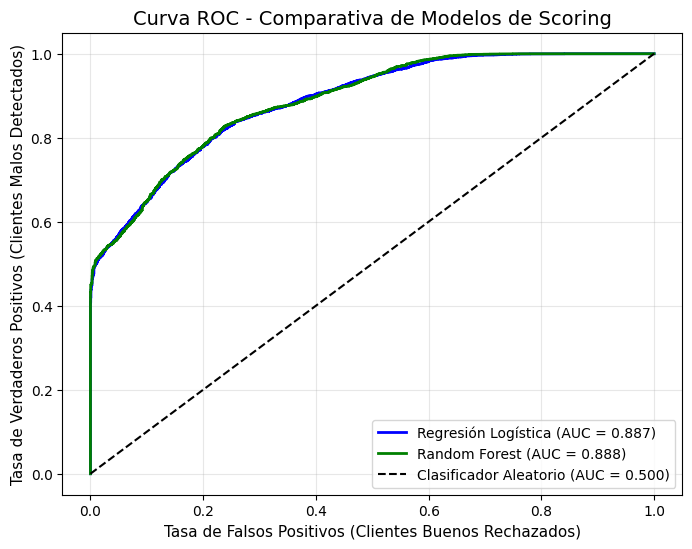

In [21]:
# -------------------------------------------------------------------
# 1. OBTENER PROBABILIDADES DE CADA MODELO
# -------------------------------------------------------------------
# Regresión Logística
y_proba = modelo_logistico.predict_proba(X_test)[:, 1]

# Random Forest
y_proba_rf = rf_model.predict_proba(X_test_rf)[:, 1]

# -------------------------------------------------------------------
# 2. GENERAR TABLA COMPARATIVA DE MÉTRICAS
# -------------------------------------------------------------------
auc_rl, gini_rl, ks_rl = calcular_metricas_riesgo(y_test, y_proba)
auc_rf, gini_rf, ks_rf = calcular_metricas_riesgo(y_test_rf, y_proba_rf)

tabla_comparativa = pd.DataFrame({
    'Métrica': ['ROC-AUC', 'Coeficiente Gini', 'Estadística KS (max)'],
    'Regresión Logística': [f"{auc_rl:.4f}", f"{gini_rl*100:.2f}%", f"{ks_rl*100:.2f}%"],
    'Random Forest': [f"{auc_rf:.4f}", f"{gini_rf*100:.2f}%", f"{ks_rf*100:.2f}%"]
})

print("=== COMPARATIVA DE DESEMPEÑO DE MODELOS ===")
print(tabla_comparativa.to_string(index=False))

# -------------------------------------------------------------------
# 3. GRÁFICO DE CURVAS ROC
# -------------------------------------------------------------------
fpr_rl, tpr_rl, _ = roc_curve(y_test, y_proba)
fpr_rf, tpr_rf, _ = roc_curve(y_test_rf, y_proba_rf)

plt.figure(figsize=(8, 6))
plt.plot(fpr_rl, tpr_rl, label=f'Regresión Logística (AUC = {auc_rl:.3f})', color='blue', linewidth=2)
plt.plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {auc_rf:.3f})', color='green', linewidth=2)
plt.plot([0, 1], [0, 1], 'k--', label='Clasificador Aleatorio (AUC = 0.500)')

plt.title('Curva ROC - Comparativa de Modelos de Scoring', fontsize=14)
plt.xlabel('Tasa de Falsos Positivos (Clientes Buenos Rechazados)', fontsize=11)
plt.ylabel('Tasa de Verdaderos Positivos (Clientes Malos Detectados)', fontsize=11)
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.show()

Vemos que 

ROC-AUC: 0.8884 | Gini: 77.67%


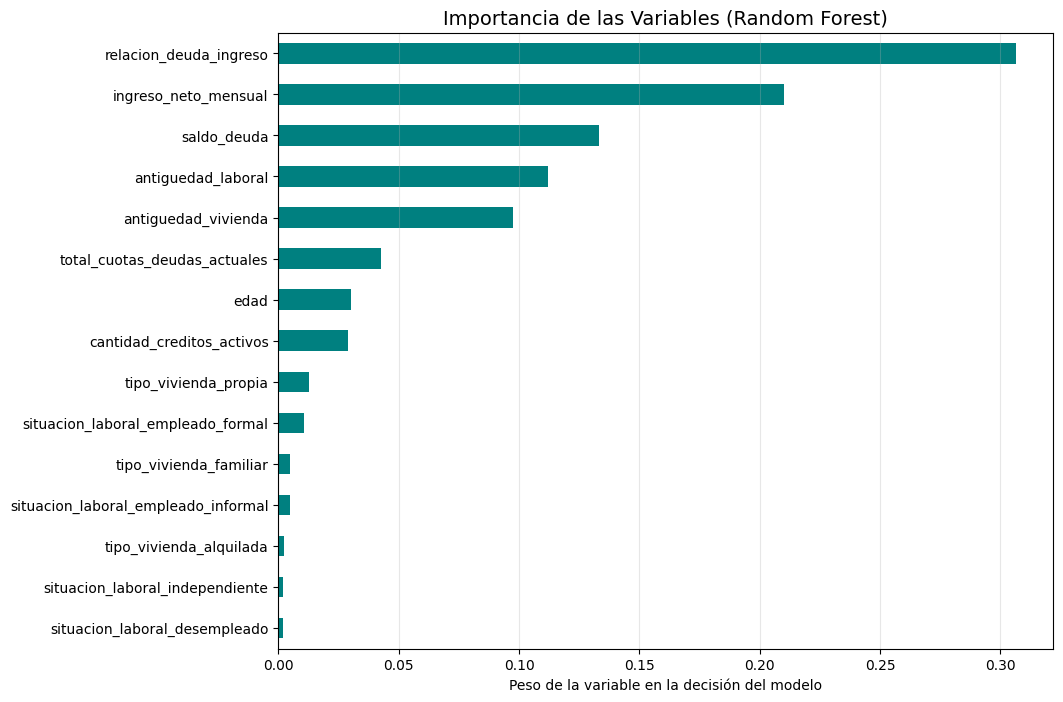

In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score

# 1. Asegúrate de que X e y estén definidos con tu lista actual de variables
# X = ... (tu dataframe con las columnas mencionadas)
# y = ... (tu target)

X_train, X_test, y_train, y_test = train_test_split(X_rf, y_rf, test_size=0.2, random_state=42, stratify=y)

# 2. Entrenar el Random Forest directamente (sin OHE, ya que tus variables son int/float)
rf_diagnostico = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42, class_weight='balanced')
rf_diagnostico.fit(X_train, y_train)

# 3. Evaluar
y_proba = rf_diagnostico.predict_proba(X_test)[:, 1]
auc = roc_auc_score(y_test, y_proba)
gini = 2 * auc - 1
print(f"ROC-AUC: {auc:.4f} | Gini: {gini*100:.2f}%")

# 4. Graficar la importancia de las variables
importancias = pd.Series(rf_diagnostico.feature_importances_, index=X.columns)
importancias_ordenadas = importancias.sort_values(ascending=True) # Ordenar para el gráfico

plt.figure(figsize=(10, 8))
importancias_ordenadas.plot(kind='barh', color='teal')
plt.title('Importancia de las Variables (Random Forest)', fontsize=14)
plt.xlabel('Peso de la variable en la decisión del modelo')
plt.grid(axis='x', alpha=0.3)
plt.show()

# Serializar el modelo

In [23]:
# Regresion Logistica
modelo_logistico_cargado = joblib.dump(modelo_logistico, 'modelo_logistico.joblib')
#Random Forest
random_forest_cargado = joblib.dump(rf_model, 'rf_modelo.joblib')